# Kratos IGA geometry: CAD JSON, STEP and freeform faces

[Kratos Multiphysics](https://github.com/KratosMultiphysics/Kratos)' isogeometric analysis
(IGA) does not keep its geometry in the `.mdpa` deck: trimmed NURBS faces, their trimming
loops and the coupling edges between them live in a **CAD JSON** file (`*.cad.json`) that its
`CadIoModeler` reads. meshio++ reads and writes that file as the `cad_json` format:

- the faces are **sampled** into the mesh as Lagrange cells, one per knot span, and a trimmed
  face keeps the cells its loops contain, so every viewer, writer and operation applies;
- the exact **B-rep** (surfaces, loops, edges, vertices) rides in `mesh.info["brep"]` and is
  written back unchanged;
- with the optional OpenCASCADE backend (`-DMESHIOPLUSPLUS_WITH_OCCT=ON`), **STEP** and **IGES**
  models read into the same side channel, so a CAD model becomes Kratos geometry by a
  conversion, and `fit_cad` turns a skin into a solid with **freeform B-spline faces**.

The fixtures are generated from closed-form geometry by `tools/gen_cad_json_fixtures.py`.
See [Kratos CAD JSON](../../doc/formats/cad_json.md).

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

os.environ.setdefault('MESHIOPLUSPLUS_LOG_LEVEL', 'error')
os.environ.setdefault('VTK_DEFAULT_OPENGL_WINDOW', 'vtkEGLRenderWindow')  # no X server
import meshioplusplus as mp  # noqa: E402
from meshioplusplus._fit_cad import has_occt  # noqa: E402

# Head-less, static rendering (no display / live server needed).
pv.OFF_SCREEN = True
pv.set_jupyter_backend('static')
TMP = tempfile.mkdtemp()
REPO = os.path.dirname(os.path.dirname(os.getcwd()))
CAD = os.path.join(REPO, 'tests', 'python', 'meshes', 'cad_json')


def to_grid(mesh):
    """A PyVista grid of a meshio++ mesh, through a temporary .vtu."""
    target = os.path.join(TMP, 'render.vtu')
    mp.write(target, mesh)
    return pv.read(target)


def render(mesh, title, scalars=None, cmap='viridis', categories=False, view=(1.0, -1.4, 1.2),
           show_edges=True):
    """Render with PyVista, or the points with matplotlib when GL is unavailable."""
    fig, ax = plt.subplots(figsize=(9, 6))
    try:
        grid = to_grid(mesh)
        pl = pv.Plotter(off_screen=True, window_size=(1000, 720))
        kwargs = {'show_edges': show_edges, 'edge_color': '#333333', 'line_width': 0.3}
        if scalars is not None:
            bar = {'title': scalars, 'vertical': True, 'position_x': 0.86,
                   'position_y': 0.15, 'height': 0.7, 'width': 0.06}
            kwargs.update(scalars=scalars, cmap=cmap, categories=categories,
                          scalar_bar_args=bar)
        else:
            kwargs['color'] = '#2ec4b6'
        pl.add_mesh(grid, **kwargs)
        pl.view_vector(view, viewup=(0, 0, 1))
        pl.reset_camera()
        img = pl.screenshot(return_img=True)
        pl.close()
        ax.imshow(img)
    except Exception as exc:  # pragma: no cover - head-less GL fallback
        print('PyVista render skipped:', exc)
        p = np.asarray(mesh.points)
        ax.scatter(p[:, 0], p[:, 1], s=1)
        ax.set_aspect('equal')
    ax.set_title(title)
    ax.axis('off')
    plt.tight_layout()
    plt.show()


def faces_only(mesh):
    """The face cells of a sampled B-rep (cad:kind 0), without the edge lines."""
    keep = [i for i, b in enumerate(mesh.cells) if mesh.cell_data['cad:kind'][i][0] == 0]
    return mp.Mesh(mesh.points, [mesh.cells[i] for i in keep],
                   cell_data={k: [v[i] for i in keep] for k, v in mesh.cell_data.items()
                              if k != 'cad:span'})


print('OpenCASCADE backend:', has_occt())

OpenCASCADE backend: True


## A trimmed plate with a hole

One degree-(2, 2) face, 4 × 4, bounded by a square **outer** loop and an **inner** loop of four
rational quadratic arcs (an exact circle of radius 1). The reader keeps the knot-span cells
whose parametric centre lies inside the loops; a trimmed face is refined to about 16 cells
per direction by default so that its trim shows, and `cad:trimmed` marks the cells the trim
crosses. The trimming curves stay exact in the side channel.

<meshio++ mesh object>
  Number of points: 932
  Number of cells:
    quad9: 204
    line: 4
    line3: 4
  Cell data: cad:id, cad:index, cad:kind, cad:span, cad:trimmed
face 2 degrees [2 2] trimmed True loops [('outer', 4), ('inner', 4)]
edges with 3-D curves: [3, 4, 5, 6, 7, 8, 9, 10]


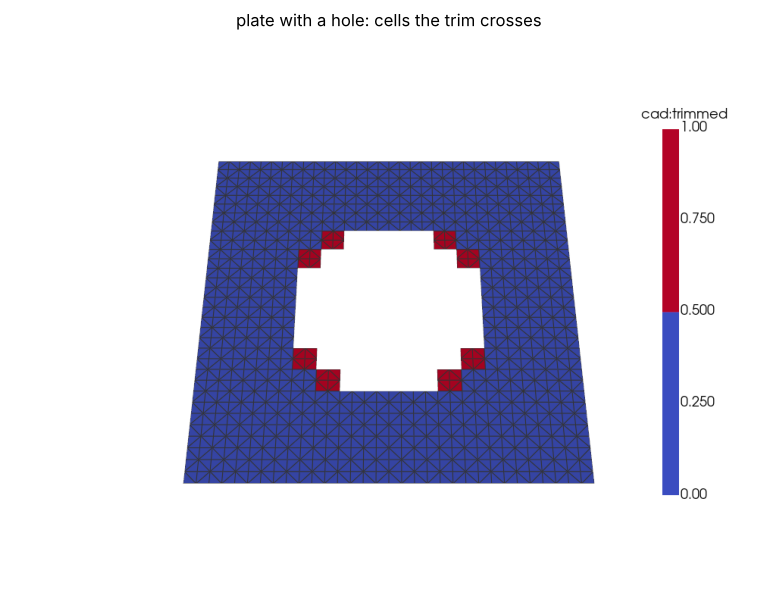

In [2]:
plate = mp.read(os.path.join(CAD, 'plate_with_hole.cad.json'))
print(plate)
brep = plate.info['brep']
face = brep['faces'][0]
print('face', face['id'], 'degrees', brep['patches'][face['patch']]['degrees'],
      'trimmed', face['trimmed'], 'loops', [(lp['type'], len(lp['trims'])) for lp in face['loops']])
print('edges with 3-D curves:', [e['id'] for e in brep['edges'] if e['curve'] is not None])
render(faces_only(plate), 'plate with a hole: cells the trim crosses', scalars='cad:trimmed',
       cmap='coolwarm', categories=True, view=(0.0, -0.6, 1.0))

The hole is staircase-accurate to a cell (constrained triangulation of the trimmed domain is a
non-goal of the core), so `subdivisions` buys a finer boundary, while `trim=False` keeps every
span. The edges are Lagrange line cells on their exact 3-D curves:

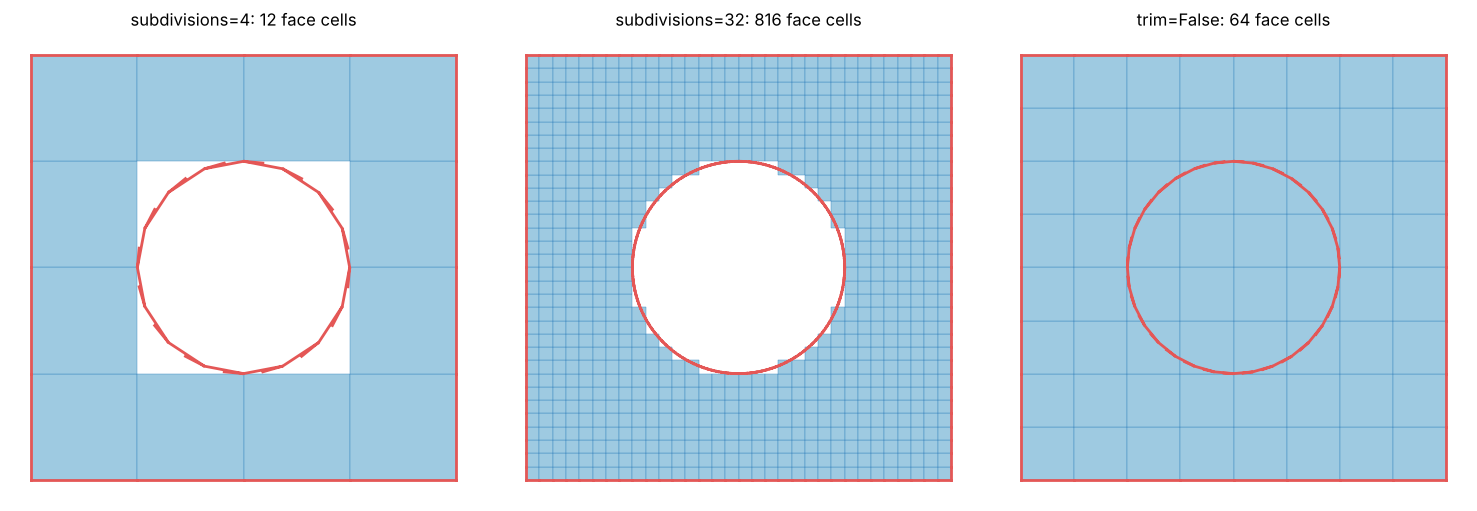

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, kwargs) in zip(axes, [('subdivisions=4', dict(subdivisions=4)),
                                       ('subdivisions=32', dict(subdivisions=32)),
                                       ('trim=False', dict(subdivisions=8, trim=False))]):
    m = mp.cad_json.read(os.path.join(CAD, 'plate_with_hole.cad.json'), **kwargs)
    for block, kind in zip(m.cells, m.cell_data['cad:kind']):
        corners = m.points[block.data[:, :4]] if kind[0] == 0 else None
        if corners is not None:
            for quad in corners:
                ax.fill(quad[:, 0], quad[:, 1], facecolor='#9ecae1', edgecolor='#3182bd', lw=0.3)
        else:
            for line in m.points[block.data]:
                ax.plot(line[:, 0], line[:, 1], color='#e45756', lw=2)
    ax.set_title(f'{title}: {sum(len(b) for b, k in zip(m.cells, m.cell_data["cad:kind"]) if k[0] == 0)} face cells')
    ax.set_aspect('equal')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Exact rational geometry: the Scordelis-Lo roof

An untrimmed rational patch of degrees (2, 1): an 80° arc of a cylinder of radius 25, its knot
vectors in Kratos's reduced form. Every sampled point lies on the cylinder to rounding, because
the sampling evaluates the rational surface exactly.

<meshio++ mesh object>
  Number of points: 289
  Number of cells:
    quad9: 64
  Cell data: cad:id, cad:index, cad:kind, cad:span, cad:trimmed
radius: min 24.999999999999996  max 25.000000000000007
knots as read (full form): [array([0., 0., 0., 1., 1., 1.]), array([ 0.,  0., 50., 50.])]
written back in the reduced form: True


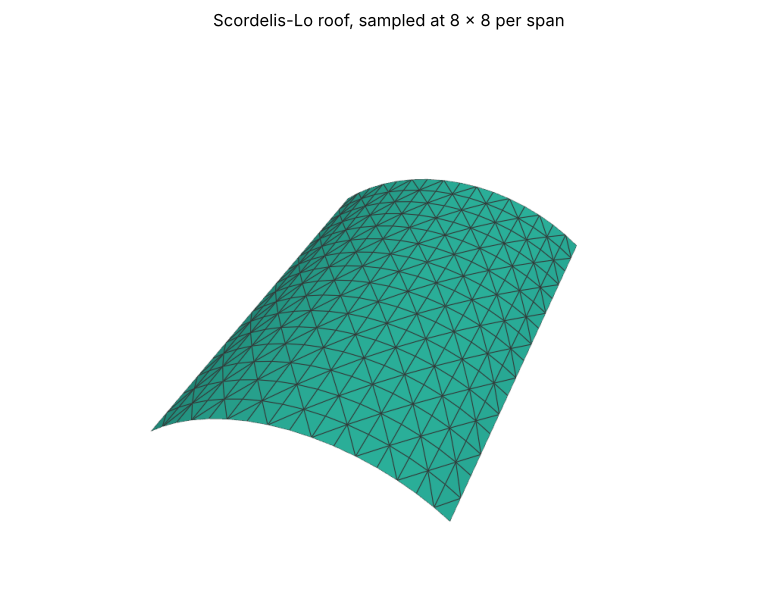

In [4]:
roof = mp.cad_json.read(os.path.join(CAD, 'cylindrical_roof.cad.json'), subdivisions=8)
p = roof.points
radius = np.hypot(p[:, 0], p[:, 2])
print(roof)
print(f'radius: min {radius.min():.15f}  max {radius.max():.15f}')
print('knots as read (full form):', roof.info['brep']['patches'][0]['knots'])
print('written back in the reduced form:', roof.info['brep']['faces'][0]['reduced_knots'])
render(roof, 'Scordelis-Lo roof, sampled at 8 x 8 per span', view=(0.4, -1.0, 0.8))

## Coupled patches, and a byte-exact round trip

Two trimmed patches (degrees (3, 2) and (2, 2)) joined by a **coupling edge** whose topology
names both faces. Points are shared within a face, not between faces: Kratos couples
neighbouring patches, it does not merge them. Writing the side channel back gives the same
bytes, members meshio++ does not model included.

edge 11 -> [(2, 0)]
edge 10 -> [(2, 1), ('right', 3)]
byte-identical rewrite: True


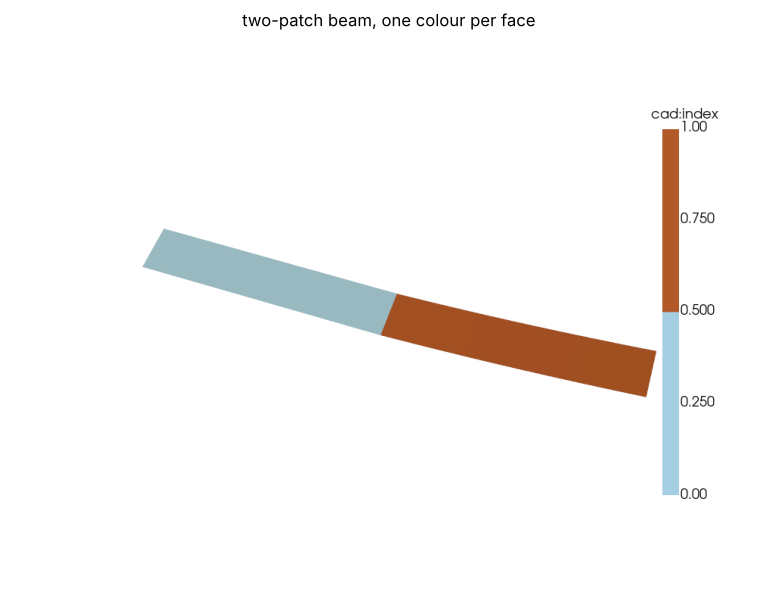

In [5]:
path = os.path.join(CAD, 'two_patch_beam.cad.json')
beam = mp.read(path)
for e in beam.info['brep']['edges']:
    print('edge', e['id'], '->', [(t['id'] if t['id'] >= 0 else t['name'], t['trim_index'])
                                   for t in e['topology']])
copy = os.path.join(TMP, 'beam.cad.json')
mp.write(copy, beam)
print('byte-identical rewrite:', open(copy, 'rb').read() == open(path, 'rb').read())
# cad:index, not cad:id: the second face is named ('right'), so its id is -1.
render(faces_only(beam), 'two-patch beam, one colour per face', scalars='cad:index',
       cmap='Paired', categories=True, view=(0.2, -0.6, 1.0), show_edges=False)

## The geometry beside an MDPA deck

A Kratos IGA project keeps the deck and its geometry side by side. `mdpa.read(..., cad_json=True)`
finds `<stem>.cad.json`, or the `geometry_file_name` of the `CadIoModeler` in a
`ProjectParameters.json` beside the deck, and attaches it as `mesh.info["brep"]`; the deck's
own mesh is unchanged.

In [6]:
import json
import shutil

project = os.path.join(TMP, 'project')
os.makedirs(project, exist_ok=True)
with open(os.path.join(project, 'model.mdpa'), 'w') as f:
    f.write('Begin Properties 0\nEnd Properties\n\nBegin Nodes\n 1 0 0 0\n 2 4 0 0\n 3 4 4 0\n'
            'End Nodes\n\nBegin Elements Element2D3N\n 1 0 1 2 3\nEnd Elements\n')
shutil.copy(os.path.join(CAD, 'plate_with_hole.cad.json'), os.path.join(project, 'geometry.cad.json'))
with open(os.path.join(project, 'ProjectParameters.json'), 'w') as f:
    json.dump({'modelers': [{'modeler_name': 'CadIoModeler',
                             'Parameters': {'geometry_file_name': 'geometry'}}]}, f)
deck = os.path.join(project, 'model.mdpa')
print('sidecar found:', os.path.basename(mp.mdpa.cad_json_path(deck)))
model = mp.mdpa.read(deck, cad_json=True)
print('deck cells:', [(b.type, len(b)) for b in model.cells],
      '| B-rep faces:', len(model.info['brep']['faces']))

sidecar found: geometry.cad.json
deck cells: [('triangle', 1)] | B-rep faces: 1


## STEP to Kratos, and freeform faces (OpenCASCADE builds)

With the backend, `fit_cad` turns a closed skin into a solid. A unit box whose top carries a
smooth bump no primitive explains comes back as five planes and one **freeform B-spline face**
(`fit_cad:type` 6); the solid's B-rep writes as CAD JSON for Kratos, and a STEP file reads back
as its triangulation plus the same kind of B-rep. Without the backend these cells only say so.

{'valid': True, 'num_plane': 5, 'num_bspline': 1, 'num_faceted_faces': 0, 'max_deviation': 0.0028822280732139142, 'tolerance': 0.004242640687119286, 'volume_ratio': 0.9999990693930507}


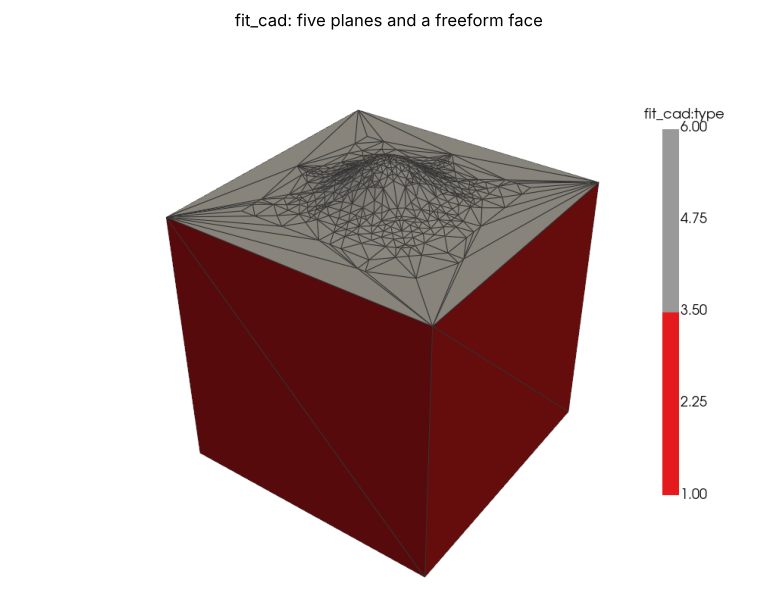

In [7]:
def bumped_box(n=32, amp=0.15):
    """The unit cube's skin, its top raised by a smooth bump."""
    g = np.linspace(0.0, 1.0, n + 1)
    pts, quads, index = [], [], {}

    def pid(x):
        key = tuple(np.round(x, 12))
        if key not in index:
            index[key] = len(pts)
            pts.append(x)
        return index[key]

    for axis in range(3):
        for side in (0.0, 1.0):
            for i in range(n):
                for j in range(n):
                    ring = []
                    for a, b in ((i, j), (i + 1, j), (i + 1, j + 1), (i, j + 1)):
                        x = np.zeros(3)
                        x[axis] = side
                        x[(axis + 1) % 3], x[(axis + 2) % 3] = g[a], g[b]
                        ring.append(pid(x))
                    quads.append(ring if side == 1.0 else ring[::-1])
    p = np.array(pts)
    top = np.isclose(p[:, 2], 1.0)
    x, y = p[top, 0], p[top, 1]
    p[top, 2] += amp * np.exp(-((x - 0.5) ** 2 + (y - 0.5) ** 2) / 0.03) * 16 * x * (1 - x) * y * (1 - y)
    return mp.Mesh(p, [('quad', np.array(quads))])


if has_occt():
    skin = bumped_box()
    fitted = mp.fit_primitives(mp.segment(skin), tolerance=1e-3)
    solid, report = mp.fit_cad(fitted, os.path.join(TMP, 'bump.step'), return_report=True)
    print({k: report[k] for k in ('valid', 'num_plane', 'num_bspline', 'num_faceted_faces',
                                  'max_deviation', 'tolerance', 'volume_ratio')})
    render(solid, 'fit_cad: five planes and a freeform face', scalars='fit_cad:type',
           cmap='Set1', categories=True)
else:
    print('this core has no OpenCASCADE backend; rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON')

CAD JSON faces: 6 | trimmed: 6
STEP read: [('triangle', 642)] | B-rep faces: 6 | edges: 12


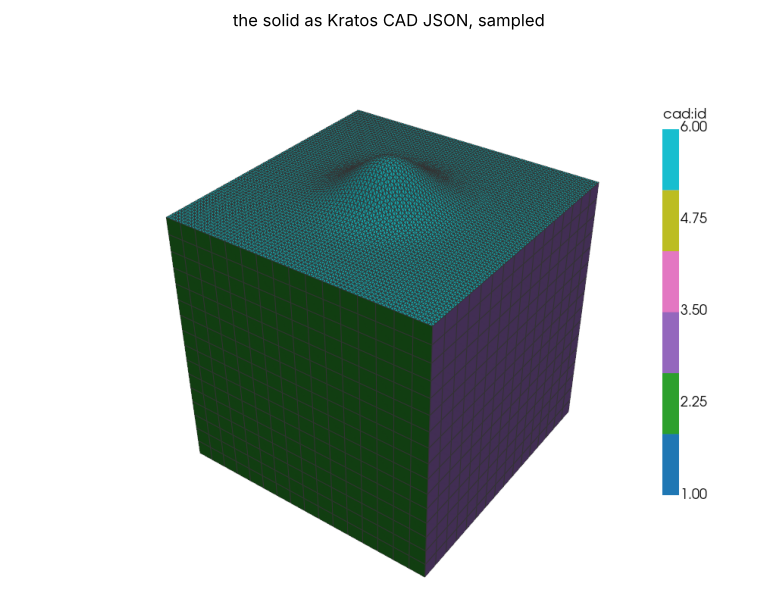

In [8]:
if has_occt():
    mp.write(os.path.join(TMP, 'bump.cad.json'), solid)              # Kratos IGA geometry
    kratos = mp.read(os.path.join(TMP, 'bump.cad.json'))
    print('CAD JSON faces:', len(kratos.info['brep']['faces']),
          '| trimmed:', sum(f['trimmed'] for f in kratos.info['brep']['faces']))
    step = mp.step.read(os.path.join(TMP, 'bump.step'), deflection=2e-3)
    print('STEP read:', [(b.type, len(b)) for b in step.cells], '| B-rep faces:',
          len(step.info['brep']['faces']), '| edges:', len(step.info['brep']['edges']))
    render(faces_only(kratos), 'the solid as Kratos CAD JSON, sampled', scalars='cad:id',
           cmap='tab10', categories=True)

## Freeform faces without a CAD kernel (v17.12.0)

`fit_cad(freeform_mode="adaptive")` fits the bump as a B-spline face with the kernel-free native backend too, and the native STEP writer writes it as a `B_SPLINE_SURFACE_WITH_KNOTS` face; `brep_checked` says OpenCASCADE did not check it. With the backend, that STEP file reads back as a B-rep and converts to Kratos CAD JSON like any other.

In [9]:
native_step = os.path.join(TMP, 'bump_native.step')
skin = bumped_box()
fitted = mp.fit_primitives(mp.segment(skin), tolerance=1e-3)
native, nreport = mp.fit_cad(fitted, native_step, backend='native', freeform_mode='adaptive', return_report=True)
text = open(native_step).read()
print({k: nreport[k] for k in ('backend', 'brep_checked', 'num_bspline', 'facet_area_fraction', 'valid')})
print('STEP entities:', {e: text.count('=' + e + '(') for e in ('ADVANCED_FACE', 'PLANE', 'B_SPLINE_SURFACE_WITH_KNOTS')})
if has_occt():
    back = mp.step.read(native_step, deflection=2e-3)
    mp.write(os.path.join(TMP, 'bump_native.cad.json'), back)
    kratos = mp.read(os.path.join(TMP, 'bump_native.cad.json'))
    print('read back by OpenCASCADE:', len(back.info['brep']['faces']), 'B-rep faces;',
          'as CAD JSON:', len(kratos.info['brep']['faces']), 'faces')

{'backend': 'native', 'brep_checked': False, 'num_bspline': 1, 'facet_area_fraction': 0.0, 'valid': True}
STEP entities: {'ADVANCED_FACE': 6, 'PLANE': 5, 'B_SPLINE_SURFACE_WITH_KNOTS': 1}
read back by OpenCASCADE: 6 B-rep faces; as CAD JSON: 6 faces
